Original Shape: (150, 2)

Number of Clusters: 3
Cluster Labels: [0 1 2]


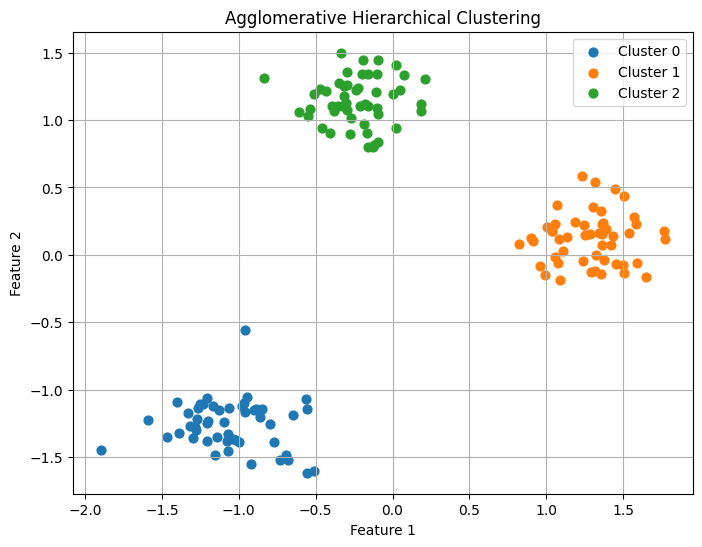

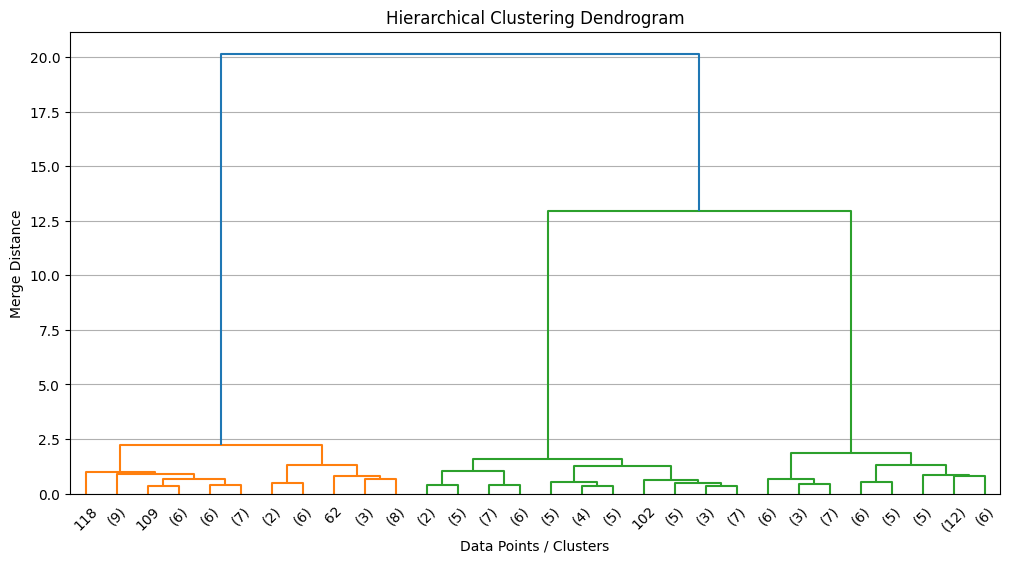

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import linkage, dendrogram

# Generate dataset
X, y_true = make_blobs(
    n_samples=150,
    centers=3,
    cluster_std=1.2,
    random_state=42
)

print("Original Shape:", X.shape)

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Hierarchical clustering using Ward linkage
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels = hierarchical.fit_predict(X_scaled)

print("\nNumber of Clusters:", len(np.unique(labels)))
print("Cluster Labels:", np.unique(labels))

# Visualize clusters
plt.figure(figsize=(8, 6))

for label in np.unique(labels):
    mask = labels == label
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=f"Cluster {label}",
        s=40
    )

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

# Create linkage matrix for dendrogram
linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Merge Distance")
plt.grid(axis="y")
plt.show()